<a href="https://colab.research.google.com/github/Desire-in-tech/predictive-maintenance-ml/blob/task-09%2Ffailure-mode-enhancement/notebooks/task_09_predictive_maintenance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 9 — Industrial Predictive Maintenance

Train an overall binary machine-failure classifier and five independent failure-mode classifiers using the UCI AI4I 2020 dataset. Mode thresholds are selected on validation data to minimize False Discovery Rate while meeting both a recall floor and a maximum FDR of 0.50. Alerting eligibility is determined exclusively from validation results. The held-out test split is reserved for final performance reporting and never changes thresholds or alerting eligibility.

**Important:** TWF, HDF, PWF, OSF and RNF are multi-label binary indicators, not five mutually exclusive classes. A row can have more than one failure-mode label. The held-out test split is never used for fitting, threshold tuning, or model-selection decisions.


In [1]:
# Install project dependencies
!pip -q install -r https://raw.githubusercontent.com/Desire-in-tech/predictive-maintenance-ml/task-09/failure-mode-enhancement/requirements.txt


In [2]:
# Clone the project branch on first run; update an existing checkout safely on reruns.
from pathlib import Path
import subprocess
import sys

repo_dir = Path('/content/predictive-maintenance-ml')
repo_url = 'https://github.com/Desire-in-tech/predictive-maintenance-ml.git'
branch = 'task-09/failure-mode-enhancement'

if (repo_dir / '.git').is_dir():
    subprocess.run(['git', '-C', str(repo_dir), 'pull', '--ff-only', 'origin', branch], check=True)
else:
    subprocess.run(['git', 'clone', '--single-branch', '--branch', branch, repo_url, str(repo_dir)], check=True)

%cd /content/predictive-maintenance-ml
sys.path.insert(0, str(repo_dir.resolve()))


/content/predictive-maintenance-ml


In [3]:
# Download the dataset and inspect the target balance
from src.data_loader import load_ai4i, FEATURES, TARGET, FAILURE_MODES
import pandas as pd
df = load_ai4i()
display(df.head())
display(df[TARGET].value_counts().rename('count').to_frame())
print(f'Rows: {len(df):,}; failure prevalence: {df[TARGET].mean():.3%}')
print('Failure-mode positive counts:')
display(df[FAILURE_MODES].sum().sort_values(ascending=False).rename('positive_rows').to_frame())


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


,count
Machine failure,
0,9661
1,339


Rows: 10,000; failure prevalence: 3.390%
Failure-mode positive counts:


,positive_rows
HDF,115
OSF,98
PWF,95
TWF,46
RNF,19


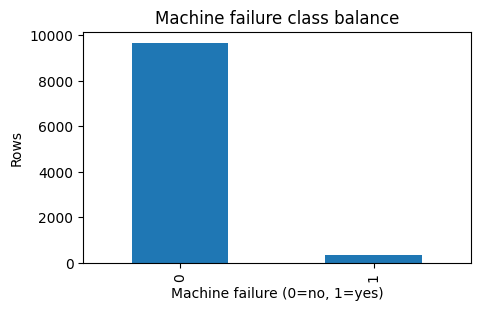

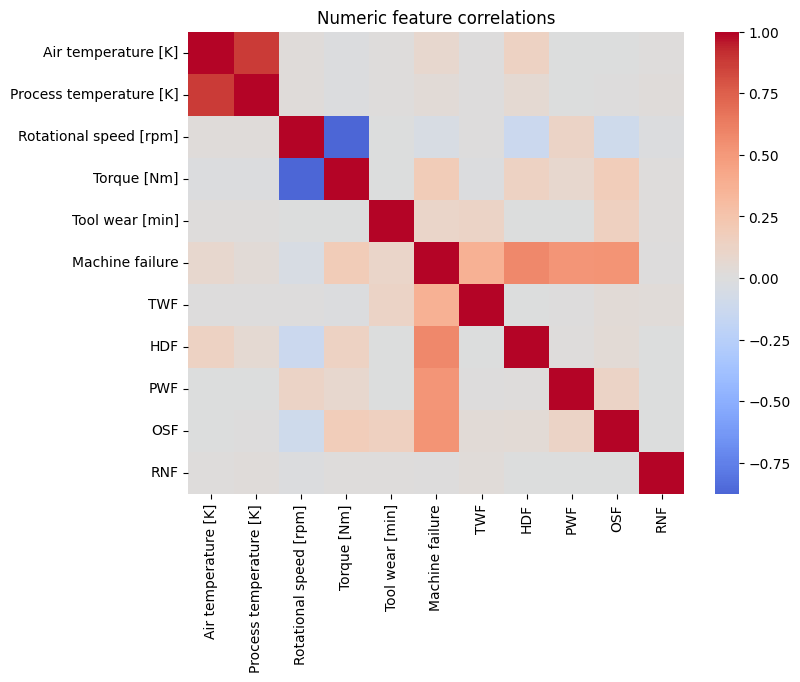

In [4]:
# Exploratory analysis: target distribution and sensor correlations
import matplotlib.pyplot as plt
import seaborn as sns
fig, ax = plt.subplots(figsize=(5, 3)); df[TARGET].value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set(title='Machine failure class balance', xlabel='Machine failure (0=no, 1=yes)', ylabel='Rows'); plt.show()
plt.figure(figsize=(8, 6)); sns.heatmap(df.select_dtypes('number').corr(), cmap='coolwarm', center=0); plt.title('Numeric feature correlations'); plt.show()


In [5]:
# Train, select a validation threshold, evaluate on held-out test data, and export artifact
!python -m src.train --output-dir artifacts --model random_forest --min-recall 0.50


{
  "threshold": 0.51,
  "precision": 0.72,
  "recall": 0.5294117647058824,
  "f1": 0.6101694915254238,
  "false_discovery_rate": 0.28,
  "false_positive_rate": 0.007246376811594203,
  "roc_auc": 0.972491170381196,
  "average_precision": 0.7277334803392069,
  "confusion_matrix": {
    "tn": 1918,
    "fp": 14,
    "fn": 32,
    "tp": 36
  },
  "model": "random_forest",
  "dataset": "UCI AI4I 2020",
  "target": "Machine failure",
  "features": [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
  ],
  "validation_recall_floor": 0.5
}
Artifact: artifacts/predictive_maintenance_pipeline.joblib


In [6]:
# Review the test metrics and saved feature schema
import json
from pathlib import Path
metrics = json.loads(Path('artifacts/metrics.json').read_text())
display(pd.DataFrame([metrics]).T.rename(columns={0:'value'}))
print(Path('artifacts/feature_schema.json').read_text())


,value
threshold,0.51
precision,0.72
recall,0.529412
f1,0.610169
false_discovery_rate,0.28
false_positive_rate,0.007246
roc_auc,0.972491
average_precision,0.727733
confusion_matrix,"{'tn': 1918, 'fp': 14, 'fn': 32, 'tp': 36}"
model,random_forest


{
  "features": [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
  ],
  "target": "Machine failure",
  "threshold": 0.51
}


# Failure-mode classification and sensor analysis

The next cells train one classifier per AI4I failure-mode indicator. Thresholds are selected on validation data using the recall floor (0.30) and maximum FDR (0.50). Alerting eligibility is determined only by whether a mode has a validation threshold satisfying both constraints. Modes without a qualifying validation threshold retain probability scores but have no exported alert threshold. The untouched test split is used only for final metric reporting; its results do not alter thresholds, model selection, or alerting eligibility. Correlations are descriptive and do not establish causality or temporal lead time.
 The same fitted estimator used for validation threshold selection is retained for test evaluation and deployment; it is not refitted after threshold selection.


In [ ]:
# Train all five failure-mode models with explicit validation recall/FDR constraints
import subprocess
import sys

training_command = [
    sys.executable, '-m', 'src.failure_modes',
    '--output-dir', 'artifacts',
    '--min-recall', '0.30',
    '--max-fdr', '0.50',
]
print('Running:', ' '.join(training_command))
subprocess.run(training_command, check=True)

# Confirm that training created all three artifacts required for inference and review.
from pathlib import Path
required_artifacts = [
    Path('artifacts/failure_modes_pipeline.joblib'),
    Path('artifacts/failure_modes_metrics.json'),
    Path('artifacts/failure_modes_schema.json'),
]
missing_artifacts = [str(path) for path in required_artifacts if not path.is_file()]
if missing_artifacts:
    raise FileNotFoundError(f'Failure-mode training did not create: {missing_artifacts}')
print('\nAll failure-mode artifacts were created successfully:')
for artifact_path in required_artifacts:
    print(f'  ✓ {artifact_path} ({artifact_path.stat().st_size:,} bytes)')


In [8]:
# Rank sensor associations with overall failure and each failure mode
from src.analysis import save_sensor_failure_correlations
correlations = save_sensor_failure_correlations(df)
display(correlations.groupby('outcome', group_keys=False).head(5))
print('Saved ranked correlations to artifacts/sensor_failure_correlations.csv')

,outcome,sensor,pearson_correlation,spearman_correlation,absolute_pearson_correlation
0,HDF,Torque [Nm],0.142610,0.138580,0.142610
1,HDF,Air temperature [K],0.137831,0.138089,0.137831
2,HDF,Rotational speed [rpm],-0.121241,-0.161262,0.121241
3,HDF,Process temperature [K],0.056933,0.063588,0.056933
4,HDF,Tool wear [min],-0.001287,-0.001599,0.001287
5,Machine failure,Torque [Nm],0.191321,0.169413,0.191321
6,Machine failure,Tool wear [min],0.105448,0.101630,0.105448
7,Machine failure,Air temperature [K],0.082556,0.083223,0.082556
8,Machine failure,Rotational speed [rpm],-0.044188,-0.167188,0.044188
9,Machine failure,Process temperature [K],0.035946,0.039946,0.035946


Saved ranked correlations to artifacts/sensor_failure_correlations.csv


In [ ]:
# Optional: persist the model artifact and reports in your Google Drive
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import shutil
destination = Path('/content/drive/MyDrive/predictive-maintenance-task09')
destination.mkdir(parents=True, exist_ok=True)

# List of expected filenames
filenames = [
    'predictive_maintenance_pipeline.joblib',
    'metrics.json',
    'feature_schema.json',
    'failure_modes_pipeline.joblib',
    'failure_modes_metrics.json',
    'failure_modes_schema.json',
    'sensor_failure_correlations.csv'
]

for filename in filenames:
    source_file = Path('artifacts') / filename
    if source_file.exists():
        shutil.copy2(source_file, destination / filename)
    else:
        print(f"Warning: {filename} not found in artifacts/ and was skipped. Please ensure you ran the training cells.")

print('Saved available versioned Task 9 outputs to:', destination)

In [10]:
# Smoke-test the same inference wrapper that Task 10 will reuse
from src.predict import PredictiveMaintenanceModel
model = PredictiveMaintenanceModel('artifacts/predictive_maintenance_pipeline.joblib')
sample = df[FEATURES].head(3).to_dict(orient='records')
model.predict(sample)


[{'failure_probability': 0.0, 'predicted_failure': False, 'threshold': 0.51},
 {'failure_probability': 0.0022515782090250175,
  'predicted_failure': False,
  'threshold': 0.51},
 {'failure_probability': 0.013541240609430193,
  'predicted_failure': False,
  'threshold': 0.51}]

In [ ]:
# Smoke-test enhanced inference and verify unavailable modes never emit alerts
import json
import pandas as pd
from pathlib import Path
from src.predict import PredictiveMaintenanceModel

artifact_path = Path('artifacts/failure_modes_pipeline.joblib')
metrics_path = Path('artifacts/failure_modes_metrics.json')
if not artifact_path.is_file() or not metrics_path.is_file():
    raise FileNotFoundError('Run the failure-mode training cell first; its model and metrics artifacts are required.')

enhanced_model = PredictiveMaintenanceModel(
    'artifacts/predictive_maintenance_pipeline.joblib',
    failure_modes_artifact_path=str(artifact_path),
)
sample = df[FEATURES].head(5).to_dict(orient='records')
enhanced_predictions = enhanced_model.predict_with_failure_modes(sample)
mode_metrics = json.loads(metrics_path.read_text())

if len(enhanced_predictions) != len(sample):
    raise AssertionError('Enhanced inference returned an unexpected number of predictions.')

rows = []
for row_number, prediction in enumerate(enhanced_predictions, start=1):
    for mode, result in prediction['failure_modes'].items():
        if result['available_for_alerting'] != (result['threshold'] is not None):
            raise AssertionError(f'{mode}: availability and threshold disagree.')
        if not result['available_for_alerting'] and result['predicted']:
            raise AssertionError(f'{mode}: unavailable mode incorrectly emitted an alert.')
        rows.append({
            'sample': row_number,
            'mode': mode,
            'probability': result['probability'],
            'threshold': result['threshold'],
            'available_for_alerting': result['available_for_alerting'],
            'predicted': result['predicted'],
        })

print(f'Enhanced inference returned {len(enhanced_predictions)} predictions for {len(sample)} sample rows.')
print('Validation-based alerting eligibility and held-out test performance:')
status_rows = []
for mode, metrics in mode_metrics.items():
    status_rows.append({
        'mode': mode,
        'status': metrics['status'],
        'test_recall': metrics['recall'],
        'test_FDR': metrics['false_discovery_rate'],
        'test_support': metrics['support'],
        'available_for_alerting': metrics['available_for_alerting'],
    })
display(pd.DataFrame(status_rows).set_index('mode'))
print('Sample-level enhanced predictions:')
display(pd.DataFrame(rows))
print('PASS: unavailable failure modes retained probability scores but emitted no alerts.')


In [ ]:
# Run the complete project test suite and fail this cell if any test fails
import subprocess
import sys

test_command = [sys.executable, '-m', 'pytest', '-v']
print('Running:', ' '.join(test_command))
test_result = subprocess.run(test_command, env={**__import__('os').environ, 'PYTHONPATH': '.'})
if test_result.returncode != 0:
    raise RuntimeError(f'Pytest failed with exit code {test_result.returncode}. Review the failures above before proceeding.')
print('\nPASS: the complete test suite finished successfully.')
